In [ ]:
import time
import numpy as np
import scipy.sparse as sp
import scipy.sparse.linalg as spla

# Parameters
n_el, T, dt, Pe = 1000, 0.5, 1e-6, 100
x0, w0 = 0.2, 0.01

h, n = 1 / n_el, n_el - 1
x = np.linspace(0, 1, n_el + 1)[1:-1]

def tri(a, b, c):
    return sp.diags([a, b, c], [-1, 0, 1], shape=(n, n), format="csc")

M = h / 6 * tri(1, 4, 1)
K = 1 / h * tri(-1, 2, -1)
C = 0.5 * tri(-1, 0, 1)
M_solve = spla.splu(M).solve

assert dt <= h**2 * Pe / 6
assert Pe * h / 2 <= 1

u = np.exp(-((x - x0) / w0)**2)
n_steps = round(T / dt)

start = time.perf_counter()

for _ in range(n_steps):
    C_u = C @ sp.diags(u)
    A_u = K / Pe + C_u
    u -= dt * M_solve(A_u @ u)

fom_time = time.perf_counter() - start
print(f"FOM runtime (Pe={Pe}): {fom_time:.3f} s")

FOM runtime (Pe=100): 343.477 s


In [ ]:
import glob
import time
import numpy as np
import scipy.sparse as sp
import scipy.linalg as la
import matplotlib.pyplot as plt
from scipy.interpolate import RBFInterpolator
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPRegressor
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import ConstantKernel, Matern, WhiteKernel
import warnings
warnings.filterwarnings("ignore")
# ------------------------------------------------------------
# Parameters
# ------------------------------------------------------------
energy_target = 0.9999
test_indices = [3, 7, 11, 15, 19]
T_eval = 0.4
max_gpr_points = 10000        # GPR costs O(n^3): time-subsample the training set above this
seed = 0

M = sp.load_npz("M.npz").toarray()
L = la.cholesky(M, lower=True)

# ------------------------------------------------------------
# Load trajectories and sort by Pe
# ------------------------------------------------------------
data = []
for filename in glob.glob("./snapshots/trajectory_*.npz"):
    with np.load(filename) as d:
        data.append((float(d["Pe"]), d["S"].copy(),
                     d["t"].copy(), d["x"].copy()))

data.sort(key=lambda item: item[0])

Pe = np.array([d[0] for d in data])
t, x = data[0][2], data[0][3]
nt = len(t)

if any(not np.allclose(d[2], t) for d in data):
    raise ValueError("Trajectories have inconsistent time grids.")
if any(d[1].shape != data[0][1].shape for d in data):
    raise ValueError("Trajectories have inconsistent snapshot shapes.")
if data[0][1].shape[0] != M.shape[0]:
    raise ValueError("Snapshot and mass matrix dimensions differ.")

test_idx = np.asarray(test_indices)
train_idx = np.setdiff1d(np.arange(len(Pe)), test_idx)

Pe_train, Pe_test = Pe[train_idx], Pe[test_idx]
S_train = np.concatenate([data[i][1] for i in train_idx], axis=1)
S_test = [data[i][1] for i in test_idx]

print(f"Training trajectories: {len(train_idx)}")
print(f"Test trajectories:     {len(test_idx)}")

Training trajectories: 76
Test trajectories:     5


In [ ]:
# ------------------------------------------------------------
# Global POD using training parameters and all times
# M = L L^T; perform SVD of L^T S_train
# ------------------------------------------------------------
Y = L.T @ S_train
U, s, _ = la.svd(Y, full_matrices=False, check_finite=False)

lam = s**2
energy = np.cumsum(lam) / np.sum(lam)
N = np.searchsorted(energy, energy_target) + 1

Z = la.solve_triangular(L.T, U[:, :N], lower=False)
A_train = U[:, :N].T @ Y                      # (N, n_train * nt)

print(f"POD modes: {N}")
print(f"Retained energy: {100 * energy[N-1]:.6f}%")

POD modes: 25
Retained energy: 99.990730%


In [ ]:
# ------------------------------------------------------------
# Regression data: (time, log10(Pe)) -> POD coefficients
# ------------------------------------------------------------
mu = np.log10(Pe)
mu_train = mu[train_idx]

X_train = np.column_stack((
    np.tile(t, len(train_idx)),
    np.repeat(mu_train, nt)
))
x_scaler = StandardScaler()
X_train = x_scaler.fit_transform(X_train)
Y_train = A_train.T                           # (n_samples, N)

# Output scaling for ANN/GPR: centre each mode, but use ONE global scale.
# The POD coefficients are M-orthonormal, so the Euclidean loss on them equals
# the M-norm error: per-mode standardisation would over-weight tiny modes.
Y_mean = Y_train.mean(axis=0)
Y_scale = (Y_train - Y_mean).std()

def to_scaled(Yv):   return (Yv - Y_mean) / Y_scale
def from_scaled(Ys): return Ys * Y_scale + Y_mean
# ------------------------------------------------------------
# Regressors. Each fit_* returns a function X_scaled -> (n, N) coefficients
# ------------------------------------------------------------
def fit_rbf(X, Yv):
    rbf = RBFInterpolator(X, Yv, kernel="thin_plate_spline",
                          neighbors=40, smoothing=0.0)
    return rbf

def fit_gpr(X, Yv):
    n = len(X)
    sub = np.arange(0, n, int(np.ceil(n / max_gpr_points)))
    print(f"   GPR trained on {len(sub)} / {n} points")

    kernel = (
        ConstantKernel(1.0, constant_value_bounds="fixed")
        * Matern(length_scale=1.0, length_scale_bounds="fixed", nu=2.5)
        + WhiteKernel(noise_level=1e-6, noise_level_bounds="fixed")
    )

    gpr = GaussianProcessRegressor(
        kernel=kernel,
        optimizer=None,
        normalize_y=False,
    )
    gpr.fit(X[sub], to_scaled(Yv[sub]))
    print(f"   GPR kernel: {gpr.kernel_}")

    return lambda Xq: from_scaled(gpr.predict(Xq))

def fit_ann(X, Yv):
    net = MLPRegressor(
        hidden_layer_sizes=(64, 64),
        activation="tanh",
        solver="adam",
        max_iter=3000,
        tol=1e-6,
        random_state=seed,
        verbose=True,
    )
    net.fit(X, to_scaled(Yv))

    plt.figure()
    plt.semilogy(net.loss_curve_)
    plt.xlabel("Iteration")
    plt.ylabel("Training loss")
    plt.tight_layout()
    plt.show()

    return lambda Xq: from_scaled(
        net.predict(Xq).reshape(len(Xq), -1)
    )

fitters = {"RBF": fit_rbf, "GPR": fit_gpr, "ANN": fit_ann}

predictors, fit_times = {}, {}
for name, fit in fitters.items():
    print(f"Training {name} ...")
    start = time.perf_counter()
    predictors[name] = fit(X_train, Y_train)
    fit_times[name] = time.perf_counter() - start
    print(f"   {name} training time: {fit_times[name]:.3f} s")


Training RBF ...
   RBF training time: 0.089 s
Training GPR ...
   GPR trained on 9510 / 76076 points


In [ ]:
# ------------------------------------------------------------
# Predict test trajectories
# ------------------------------------------------------------
def err_M(D):
    return np.sqrt(np.maximum(np.sum(D * (M @ D), axis=0), 0.0))

methods = list(fitters)
U_pred = {m: [] for m in methods}
errors = {m: [] for m in methods}
pred_times = {m: [] for m in methods}
U_proj, proj_errors = [], []

for j, (Pe_j, S_j) in enumerate(zip(Pe_test, S_test)):
    X_test = x_scaler.transform(np.column_stack((t, np.full(nt, np.log10(Pe_j)))))

    # Best approximation in the same POD space
    U_j_proj = Z @ (Z.T @ M @ S_j)
    U_proj.append(U_j_proj)
    proj_errors.append(err_M(S_j - U_j_proj))

    for m in methods:
        start = time.perf_counter()
        A_pred = np.asarray(predictors[m](X_test)).T      # (N, nt)
        U_j = Z @ A_pred
        pred_times[m].append(time.perf_counter() - start)
        U_pred[m].append(U_j)
        errors[m].append(err_M(S_j - U_j))

In [ ]:
# ------------------------------------------------------------
# Summary table
# ------------------------------------------------------------
print("\nMean-in-time error (M-norm) per test Pe")
print(f"{'Pe':>9} {'Projection':>12} " +
      " ".join(f"{m:>12}" for m in methods))

for j, Pe_j in enumerate(Pe_test):
    print(f"{Pe_j:9.2f} {np.mean(proj_errors[j]):12.3e} " +
          " ".join(f"{np.mean(errors[m][j]):12.3e}" for m in methods))

print(f"\nError at t = {T_eval:.2f}")
k = np.argmin(np.abs(t - T_eval))
for j, Pe_j in enumerate(Pe_test):
    print(f"{Pe_j:9.2f} {proj_errors[j][k]:12.3e} " +
          " ".join(f"{errors[m][j][k]:12.3e}" for m in methods))

# ------------------------------------------------------------
# Cost and speed-up
# ------------------------------------------------------------
print("\nCost and speed-up")
print(f"{'Method':<15} {'Training [s]':>14} {'Online [s]':>14} {'Speed-up':>12}")

for m in methods:
    online = np.mean(pred_times[m])
    fom = 350
    speedup = fom / online if online > 0 else np.nan

    print(f"{m:<15} {fit_times[m]:14.3f} {online:14.4f} {speedup:11.2f}x")


Mean-in-time error (M-norm) per test Pe
       Pe   Projection          RBF          GPR          ANN
    11.89    2.355e-04    3.828e-04    3.550e-04    8.633e-04
    14.96    1.883e-04    3.170e-04    3.054e-04    7.619e-04
    18.84    1.946e-04    3.056e-04    3.877e-04    7.407e-04
    23.71    1.987e-04    2.927e-04    2.924e-04    7.181e-04
    29.85    1.815e-04    2.604e-04    2.893e-04    6.972e-04

Error at t = 0.40
    11.89    2.478e-04    2.481e-04    2.478e-04    4.818e-04
    14.96    9.267e-05    9.331e-05    9.267e-05    4.122e-04
    18.84    1.991e-04    1.993e-04    1.991e-04    4.733e-04
    23.71    2.331e-04    2.333e-04    2.331e-04    4.295e-04
    29.85    1.873e-04    1.876e-04    1.873e-04    3.531e-04

Cost and speed-up
Method            Training [s]     Online [s]     Speed-up
RBF                      0.029         0.1952     1792.76x
GPR                     35.574         3.8932       89.90x
ANN                    126.426         0.0123    28433.77x


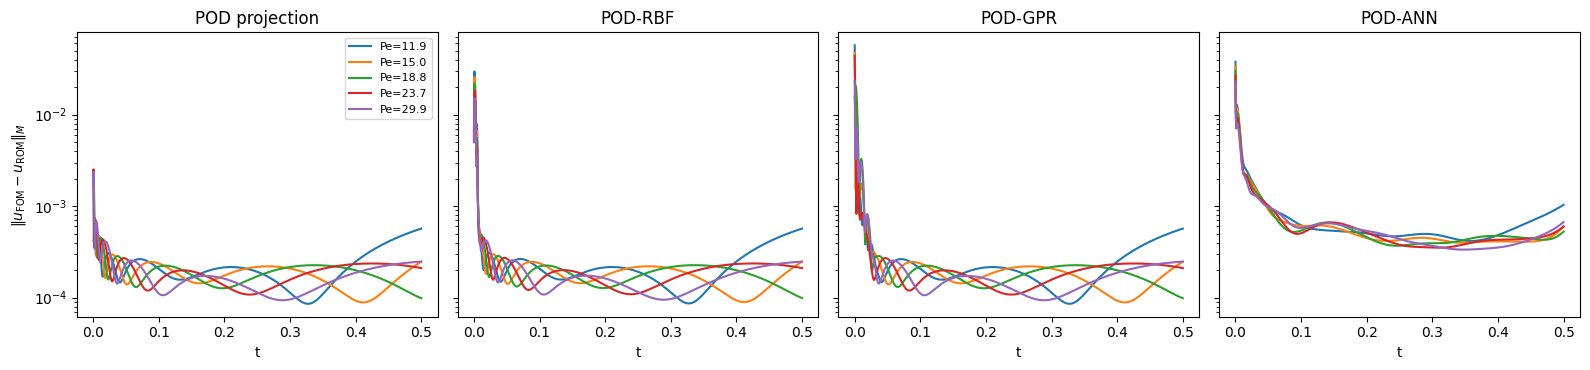

In [ ]:
# ------------------------------------------------------------
# Plot 1: error evolution in time, one panel per method
# ------------------------------------------------------------
fig, axs = plt.subplots(1, len(methods) + 1, figsize=(4 * (len(methods) + 1), 3.8),
                        sharey=True)
for Pe_j, ep in zip(Pe_test, proj_errors):
    axs[0].semilogy(t, ep, label=f"Pe={Pe_j:.1f}")
axs[0].set_title("POD projection")
for ax, m in zip(axs[1:], methods):
    for Pe_j, e in zip(Pe_test, errors[m]):
        ax.semilogy(t, e, label=f"Pe={Pe_j:.1f}")
    ax.set_title(f"POD-{m}")
for ax in axs:
    ax.set_xlabel("t")
axs[0].set_ylabel(r"$\|u_{\mathrm{FOM}}-u_{\mathrm{ROM}}\|_M$")
axs[0].legend(fontsize=8)
fig.tight_layout()

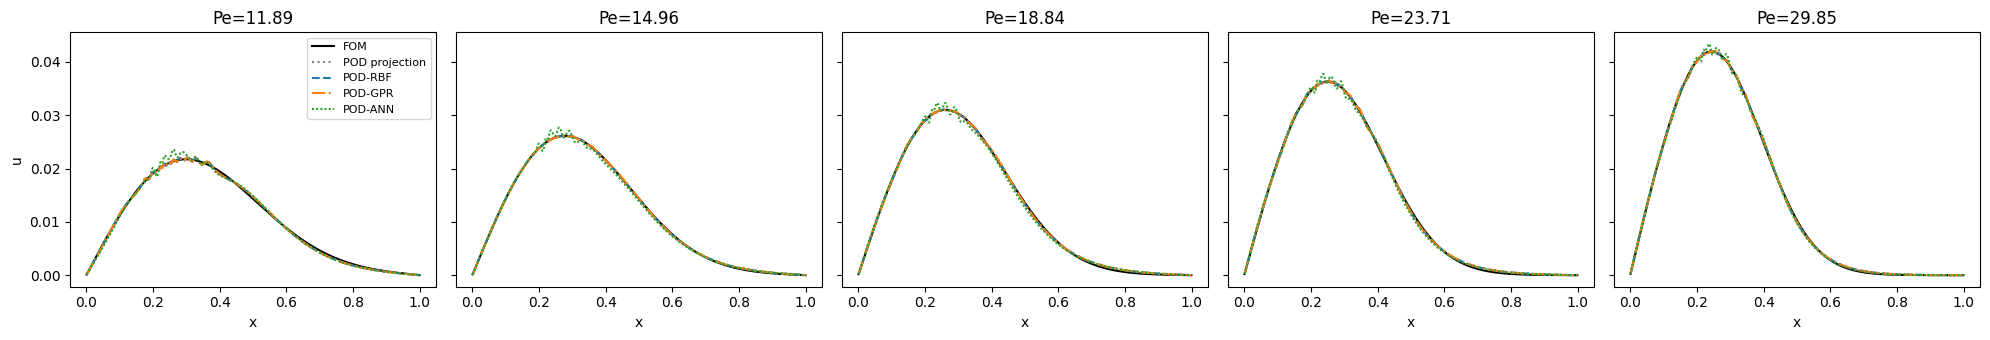

In [ ]:
# ------------------------------------------------------------
# Plot 2: profiles at t = 0.4
# ------------------------------------------------------------
styles = {"RBF": "--", "GPR": "-.", "ANN": (0, (1, 1))}
fig, axs = plt.subplots(1, len(Pe_test), figsize=(4 * len(Pe_test), 3.5), sharey=True)
axs = np.atleast_1d(axs)
for j, ax in enumerate(axs):
    ax.plot(x, S_test[j][:, k], "k-", label="FOM")
    ax.plot(x, U_proj[j][:, k], ":", color="gray", label="POD projection")
    for m in methods:
        ax.plot(x, U_pred[m][j][:, k], ls=styles[m], label=f"POD-{m}")
    ax.set_title(f"Pe={Pe_test[j]:.2f}")
    ax.set_xlabel("x")
axs[0].set_ylabel("u")
axs[0].legend(fontsize=8)
fig.tight_layout()

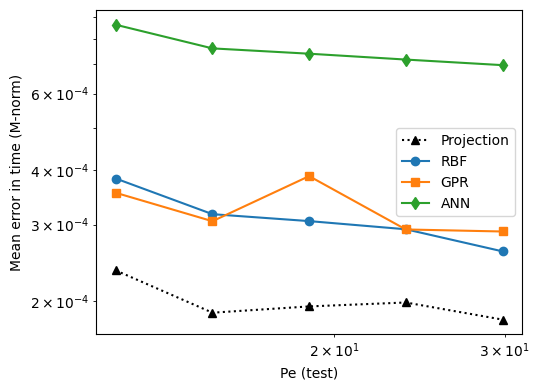

In [ ]:
# ------------------------------------------------------------
# Plot 3: mean error vs test Pe, all methods
# ------------------------------------------------------------
fig = plt.figure(figsize=(5.5, 4))
plt.semilogy(Pe_test, [np.mean(e) for e in proj_errors], "k^:", label="Projection")
for m, mk in zip(methods, "osd"):
    plt.semilogy(Pe_test, [np.mean(e) for e in errors[m]], mk + "-", label=m)
plt.xscale("log")
plt.xlabel("Pe (test)")
plt.ylabel("Mean error in time (M-norm)")
plt.legend()
fig.tight_layout()